## Question 2.1: SARSA vs Q-Learning Implementation

This section implements and compares SARSA and Q-Learning algorithms on the Cliff Walking environment.

**Key Implementation Details:**
- Implemented SARSA update formula: uses the next action sampled from the epsilon-greedy policy
- Implemented Q-Learning update formula: uses the maximum Q-value of the next state
- Both algorithms are trained for 500 episodes over 100 independent runs
- Results show learning curves and learned optimal policies

In [1]:
import numpy as np
import matplotlib

from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'notebook')
import matplotlib.pyplot as plt
from IPython.display import Image, display
from tqdm import tqdm  # show the progress of iteration runs in the console

# World height
WORLD_HEIGHT = 4

# World width
WORLD_WIDTH = 6

# Probability for epsilon-greedy actions
EPSILON = 0.1

# step size/learning rate, choose between (0,1)
ALPHA = 0.1

# Discount factor
GAMMA = 1

# Actions
ACTION_UP = 0
ACTION_DOWN = 1
ACTION_LEFT = 2
ACTION_RIGHT = 3
ACTIONS = [ACTION_UP, ACTION_DOWN, ACTION_LEFT, ACTION_RIGHT]

# Start and Goal state coordinates
START = [WORLD_HEIGHT - 1, 0]
GOAL = [WORLD_HEIGHT - 1, WORLD_WIDTH - 1]


# Transition dynamics and reward function
def step(state, action):
    i, j = state
    if action == ACTION_UP:
        next_state = [max(i - 1, 0), j]
    elif action == ACTION_LEFT:
        next_state = [i, max(j - 1, 0)]
    elif action == ACTION_RIGHT:
        next_state = [i, min(j + 1, WORLD_WIDTH - 1)]
    elif action == ACTION_DOWN:
        next_state = [min(i + 1, WORLD_HEIGHT - 1), j]
    else:
        assert False

    reward = -1
    # Fall off the cliff, get reward -100, and reset the state to START
    if (action == ACTION_DOWN and i == WORLD_HEIGHT - 2 and 1 <= j <= WORLD_WIDTH - 2) or (
            action == ACTION_RIGHT and state == START):
        reward = -300
        next_state = START

    return next_state, reward


# Epsilon-greedy policy
def choose_action(state, q_value, epsilon=EPSILON):
    if np.random.binomial(1, epsilon) == 1:  # with EPSILON chance, choose a random action
        return np.random.choice(ACTIONS)
    else:  # choose greedy action
        values_ = q_value[state[0], state[1], :]
        # Syntax: for index, value in enumerate(list)
        return np.random.choice([action_ for action_, value_ in enumerate(values_) if value_ == np.max(values_)])


# One episode with Sarsa
# @q_value: action values for state-action pairs, to be estimated
# @step_size: step size/learning rate
# @return: sum of rewards received during this episode
def sarsa(q_value, step_size=ALPHA):
    state = START
    action = choose_action(state, q_value)
    rewards = 0.0
    while state != GOAL:
        next_state, reward = step(state, action)
        next_action = choose_action(next_state, q_value)
        rewards += reward
        # TODO: implement SARSA update formula
        q_value[state[0], state[1], action] += step_size * (
        reward + GAMMA * q_value[next_state[0], next_state[1], next_action]
        - q_value[state[0], state[1], action]
        )

        state = next_state
        action = next_action
    return rewards


# One episode with Q-Learning
def q_learning(q_value, step_size=ALPHA):
    state = START
    rewards = 0.0
    while state != GOAL:
        action = choose_action(state, q_value)
        next_state, reward = step(state, action)
        rewards += reward
        # TODO: implement Q-learning update formula
        q_value[state[0], state[1], action] += step_size * (
        reward + GAMMA * np.max(q_value[next_state[0], next_state[1], :])
        - q_value[state[0], state[1], action]
        )

        state = next_state
    return rewards


# @q_value: greedy action is taken from the given q_value
# @return: sum of rewards received by following the (greedy) policy
def deploy_learned_policy(q_value):
    state = START
    epsilon = 0  # greedy action
    action = choose_action(state, q_value, epsilon)
    rewards = 0.0
    while state != GOAL:
        next_state, reward = step(state, action)
        next_action = choose_action(next_state, q_value, epsilon)
        rewards += reward
        state = next_state
        action = next_action
    return rewards


def display_optimal_policy(q_value):
    optimal_policy = []
    for i in range(0, WORLD_HEIGHT):
        optimal_policy.append([])
        for j in range(0, WORLD_WIDTH):
            if [i, j] == GOAL:
                optimal_policy[-1].append('G')
                continue
            bestAction = np.argmax(q_value[i, j, :])
            if bestAction == ACTION_UP:
                optimal_policy[-1].append('U')
            elif bestAction == ACTION_DOWN:
                optimal_policy[-1].append('D')
            elif bestAction == ACTION_LEFT:
                optimal_policy[-1].append('L')
            elif bestAction == ACTION_RIGHT:
                optimal_policy[-1].append('R')
    for row in optimal_policy:
        print(row)


# Perform multiple independent runs and average to obtain smoothed return curves against the number of trained episodes.
# The curve of a single run will be very volatile
def Online_Performance():
    # episodes of each run
    episodes = 500
    # perform 50 independent runs
    runs = 100

    rewards_sarsa = np.zeros(episodes)
    rewards_q_learning = np.zeros(episodes)
    for r in tqdm(range(runs)):
        Q_sarsa = np.zeros((WORLD_HEIGHT, WORLD_WIDTH, 4))
        Q_q_learning = np.copy(Q_sarsa)
        for i in range(0, episodes):
            # numpy array is mutable data type. Hence, pass its address to the function.
            rewards_sarsa[i] += sarsa(Q_sarsa)
            rewards_q_learning[i] += q_learning(Q_q_learning)

    # Take the average over all independent runs
    rewards_sarsa /= runs
    rewards_q_learning /= runs

    plt.figure()
    plt.plot(rewards_sarsa, label='Sarsa')
    plt.plot(rewards_q_learning, label='Q-Learning', linestyle='dashed')
    plt.xlabel('Episodes')
    plt.ylabel('Sum of rewards during episode')
    plt.ylim([-130, 10])
    plt.legend(loc='upper left')
    plt.grid()
    plt.savefig('Online_Performance_Comparison.png')
    display(Image('Online_Performance_Comparison.png'))
    plt.close()

    # Display optimal policy
    print('Sarsa Optimal Policy:')
    display_optimal_policy(Q_sarsa)
    print('Q-Learning Optimal Policy:')
    display_optimal_policy(Q_q_learning)
    return Q_sarsa, Q_q_learning

100%|██████████| 100/100 [00:51<00:00,  1.92it/s]


<IPython.core.display.Javascript object>

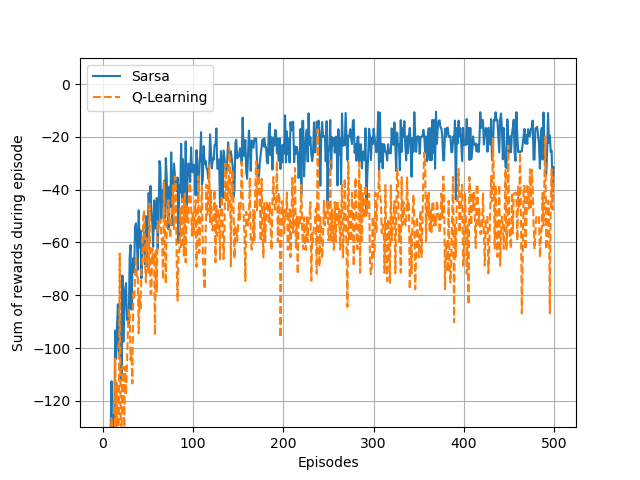

Sarsa Optimal Policy:
['R', 'U', 'R', 'R', 'D', 'D']
['R', 'R', 'R', 'R', 'R', 'D']
['U', 'U', 'U', 'U', 'R', 'D']
['U', 'U', 'U', 'U', 'U', 'G']
Q-Learning Optimal Policy:
['D', 'R', 'R', 'U', 'U', 'U']
['R', 'U', 'D', 'R', 'D', 'D']
['R', 'R', 'R', 'R', 'R', 'D']
['U', 'U', 'U', 'U', 'U', 'G']


In [2]:
Q_sarsa, Q_q_learning = Online_Performance()

## Question 2.2: Greedy Policy Evaluation

After training for 500 episodes in Question 1, we evaluate the learned policies by running 200 episodes with greedy action selection (ε = 0).

**Evaluation Setup:**
- Use the trained Q-functions from Question 1
- Run 200 test episodes with greedy policy (no exploration)
- Calculate average return and cumulative rewards
- Compare performance between SARSA and Q-Learning learned policies

In [3]:

def Evaluate_Greedy_After_Training(Q_sarsa, Q_q_learning):
    episodes_test = 200

    # During evaluation, we use greedy policy (epsilon = 0)
    epsilon_backup = 0.1
    EPSILON = 0.0

    rewards_sarsa = np.zeros(episodes_test)
    rewards_q = np.zeros(episodes_test)

    for ep in range(episodes_test):
        rewards_sarsa[ep] = deploy_learned_policy(Q_sarsa)
        rewards_q[ep] = deploy_learned_policy(Q_q_learning)

    # Restore epsilon
    EPSILON = epsilon_backup

    plt.figure()
    cum_sarsa = np.cumsum(rewards_sarsa)
    cum_q = np.cumsum(rewards_q)
    plt.plot(cum_sarsa, label='SARSA Greedy Policy')
    plt.plot(cum_q, label='Q-learning Greedy Policy', linestyle='dashed')
    plt.xlabel('Episode')
    plt.ylabel('Cumulative reward')
    plt.title('Greedy Policy Evaluation after 500-episode Training')
    plt.grid()
    plt.legend()
    plt.savefig('Greedy_Policy_Test.png')
    plt.show()
    plt.close()

    print("==== Greedy Test Completed ====")
    print("Average return SARSA :", np.mean(rewards_sarsa))
    print("Average return Q-Learning :", np.mean(rewards_q))
    print("Cumulative reward SARSA :", np.sum(rewards_sarsa))
    print("Cumulative reward Q-Learning :", np.sum(rewards_q))

In [5]:
Evaluate_Greedy_After_Training(Q_sarsa, Q_q_learning)

<IPython.core.display.Javascript object>

==== Greedy Test Completed ====
Average return SARSA : -9.0
Average return Q-Learning : -7.0
Cumulative reward SARSA : -1800.0
Cumulative reward Q-Learning : -1400.0


## Question 2.3: SARSA with Decaying Epsilon

Modify SARSA to use a time-dependent epsilon schedule: ε_t = 1/(10t + 1), where t is the episode number. Q-Learning continues to use a fixed ε = 0.1.

**Key Changes:**
- SARSA uses decaying epsilon: ε_t = 1/(10t + 1)
- Q-Learning maintains fixed epsilon: ε = 0.1
- Train for 500 episodes over 100 independent runs
- Evaluate with 200 greedy episodes after training

<IPython.core.display.Javascript object>

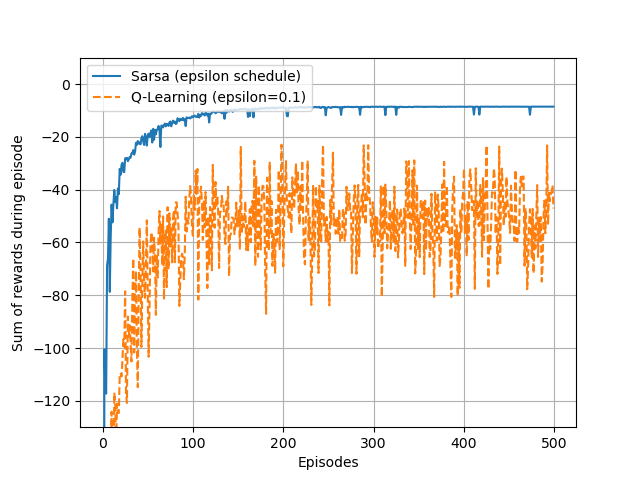

Sarsa Optimal Policy (Q3):
['R', 'R', 'D', 'R', 'R', 'D']
['R', 'R', 'R', 'R', 'R', 'D']
['U', 'R', 'R', 'R', 'R', 'D']
['U', 'U', 'U', 'U', 'U', 'G']
Q-Learning Optimal Policy (Q3):
['U', 'U', 'U', 'R', 'R', 'D']
['R', 'R', 'R', 'D', 'D', 'D']
['R', 'R', 'R', 'R', 'R', 'D']
['U', 'U', 'U', 'U', 'U', 'G']


<IPython.core.display.Javascript object>

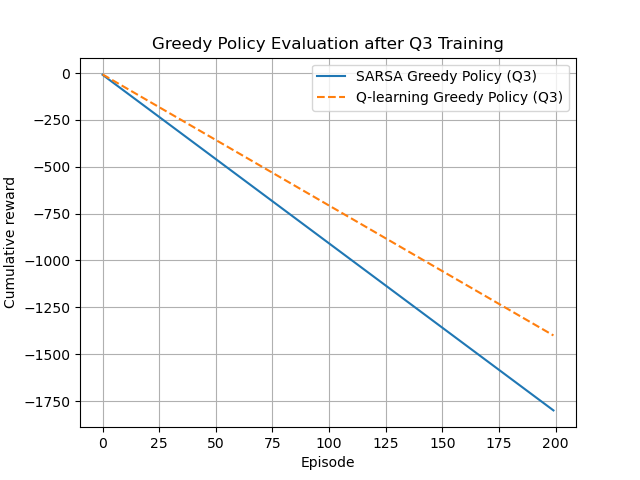

==== Greedy Test Q3 Completed ====
Average return SARSA : -9.0
Average return Q-Learning : -7.0
Cumulative reward SARSA : -1800.0
Cumulative reward Q-Learning : -1400.0


In [6]:
def sarsa_with_epsilon(q_value, epsilon, step_size=ALPHA):
    state = START
    action = choose_action(state, q_value, epsilon)
    rewards = 0.0
    while state != GOAL:
        next_state, reward = step(state, action)
        next_action = choose_action(next_state, q_value, epsilon)
        rewards += reward
        q_value[state[0], state[1], action] += step_size * (
            reward + GAMMA * q_value[next_state[0], next_state[1], next_action]
            - q_value[state[0], state[1], action]
        )
        state = next_state
        action = next_action
    return rewards

def Online_Performance_Q3():
    episodes = 500
    runs = 100
    rewards_sarsa = np.zeros(episodes)
    rewards_q_learning = np.zeros(episodes)
    for r in range(runs):
        Q_sarsa = np.zeros((WORLD_HEIGHT, WORLD_WIDTH, 4))
        Q_q_learning = np.copy(Q_sarsa)
        for t in range(episodes):
            eps_t = 1.0 / (10 * t + 1)
            rewards_sarsa[t] += sarsa_with_epsilon(Q_sarsa, eps_t)
            rewards_q_learning[t] += q_learning(Q_q_learning)
    rewards_sarsa /= runs
    rewards_q_learning /= runs
    plt.figure()
    plt.plot(rewards_sarsa, label='Sarsa (epsilon schedule)')
    plt.plot(rewards_q_learning, label='Q-Learning (epsilon=0.1)', linestyle='dashed')
    plt.xlabel('Episodes')
    plt.ylabel('Sum of rewards during episode')
    plt.ylim([-130, 10])
    plt.legend(loc='upper left')
    plt.grid()
    plt.savefig('Online_Performance_Q3.png')
    display(Image('Online_Performance_Q3.png'))
    plt.close()
    print('Sarsa Optimal Policy (Q3):')
    display_optimal_policy(Q_sarsa)
    print('Q-Learning Optimal Policy (Q3):')
    display_optimal_policy(Q_q_learning)
    return Q_sarsa, Q_q_learning

def Evaluate_Greedy_After_Training_Q3(Q_sarsa, Q_q_learning):
    episodes_test = 200
    rewards_sarsa = np.zeros(episodes_test)
    rewards_q = np.zeros(episodes_test)
    for ep in range(episodes_test):
        rewards_sarsa[ep] = deploy_learned_policy(Q_sarsa)
        rewards_q[ep] = deploy_learned_policy(Q_q_learning)
    plt.figure()
    cum_sarsa = np.cumsum(rewards_sarsa)
    cum_q = np.cumsum(rewards_q)
    plt.plot(cum_sarsa, label='SARSA Greedy Policy (Q3)')
    plt.plot(cum_q, label='Q-learning Greedy Policy (Q3)', linestyle='dashed')
    plt.xlabel('Episode')
    plt.ylabel('Cumulative reward')
    plt.title('Greedy Policy Evaluation after Q3 Training')
    plt.grid()
    plt.legend()
    plt.savefig('Greedy_Policy_Test_Q3.png')
    display(Image('Greedy_Policy_Test_Q3.png'))
    plt.close()
    print('==== Greedy Test Q3 Completed ====')
    print('Average return SARSA :', np.mean(rewards_sarsa))
    print('Average return Q-Learning :', np.mean(rewards_q))
    print('Cumulative reward SARSA :', np.sum(rewards_sarsa))
    print('Cumulative reward Q-Learning :', np.sum(rewards_q))

Q_sarsa_Q3, Q_q_learning_Q3 = Online_Performance_Q3()
Evaluate_Greedy_After_Training_Q3(Q_sarsa_Q3, Q_q_learning_Q3)
